# Grafos dinámicos: el grafo se arma en cada pasada

En el módulo 1 vimos que `backward()` calcula los gradientes recorriendo hacia atrás un grafo con las operaciones que produjeron la pérdida (`04-matematica-de-pytorch/01_autograd_y_regla_de_la_cadena`, sección 3). Ese notebook miró el grafo de una sola cuenta. Este mira algo que allí no se notaba: **cuándo** se construye ese grafo. En PyTorch se construye mientras corre `forward`, se arma de nuevo en cada pasada y se descarta después de `backward()`. Por eso se dice que PyTorch usa **grafos dinámicos**.

El video *Dynamic Graphs* del curso lo presenta con la app del jardín botánico: si un mismo modelo tiene que reconocer flores y mariposas, `forward` puede decidir con un `if` qué parte de la red usar. Este notebook comprueba en código qué permite eso y cuánto cuesta:

- cómo se ve el grafo de una cuenta y cómo recorrerlo entero;
- que cada pasada arma un grafo nuevo, y que `backward()` lo libera;
- que un `if` o un bucle cambian el grafo, y que los gradientes siguen siendo correctos;
- una red con dos cabezas, en la que solo la cabeza usada recibe gradiente;
- entradas de largo variable, que reutilizan los mismos parámetros;
- `print` y *hooks* para mirar adentro de un modelo;
- una red con salida temprana, que gasta menos en los casos fáciles;
- qué pasa cuando se intenta convertir un modelo con un `if` en un grafo fijo;
- cuánto cuesta, medido, que el grafo se arme en cada pasada.

Usamos tensores chicos y Fashion-MNIST, que se descarga en `modulo-4/data`. El notebook tarda entre uno y dos minutos en una CPU.

**Contenido**

1. Preparación
2. El grafo de una cuenta
3. Un grafo nuevo en cada pasada
4. `if` y bucles cambian el grafo
5. Una red con dos cabezas
6. Entradas de largo variable
7. Mirar adentro: `print` y hooks
8. Salida temprana: menos cómputo para lo fácil
9. Grafos estáticos
10. Lo que cuesta un grafo dinámico
11. Resumen y ejercicios

## 1. Preparación

Fashion-MNIST tiene la misma forma que MNIST (imágenes de 28 × 28 en escala de grises, 60.000 de entrenamiento y 10.000 de prueba), pero con fotos de ropa, calzado y bolsos en vez de dígitos. Como cabe en memoria, lo precargamos normalizado, igual que en `00-datos/01_transforms_dataset_y_dataloader` del módulo 2, y así cada entrenamiento de este notebook toma segundos.

In [1]:
import textwrap
import time
import warnings
from collections import Counter

import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"       # modulo-4/data


def precargar(entrenamiento):
    datos = datasets.FashionMNIST(root=RAIZ, train=entrenamiento, download=True)
    return datos.data.float().unsqueeze(1) / 255, datos.targets     # [N, 1, 28, 28] entre 0 y 1


X_entrenamiento, y_entrenamiento = precargar(True)
X_prueba, y_prueba = precargar(False)
MEDIA, DESVIACION = X_entrenamiento.mean().item(), X_entrenamiento.std().item()
X_entrenamiento = (X_entrenamiento - MEDIA) / DESVIACION
X_prueba = (X_prueba - MEDIA) / DESVIACION

CLASES = ["camiseta", "pantalón", "suéter", "vestido", "abrigo",
          "sandalia", "camisa", "zapatilla", "bolso", "botín"]
print(f"entrenamiento {tuple(X_entrenamiento.shape)}   prueba {tuple(X_prueba.shape)}")
print(f"media {MEDIA:.4f}   desviación {DESVIACION:.4f}  (calculadas con el entrenamiento)")


def mostrar_error(error):
    """Imprime el tipo y el mensaje de un error, cortado en líneas de 100 caracteres."""
    print(type(error).__name__ + ":")
    print(textwrap.fill(str(error), 100))

Versión de PyTorch: 2.11.0+cpu


entrenamiento (60000, 1, 28, 28)   prueba (10000, 1, 28, 28)
media 0.2860   desviación 0.3530  (calculadas con el entrenamiento)


## 2. El grafo de una cuenta

Una neurona con dos entradas y activación `tanh`:

$$s = w_1 x_1 + w_2 x_2 + b, \qquad y = \tanh(s)$$

Los pesos $w_1$, $w_2$ y $b$ piden gradiente; las entradas $x_1$ y $x_2$ son datos y no lo piden. La documentación de PyTorch, en [*How autograd encodes the history*](https://docs.pytorch.org/docs/stable/notes/autograd.html#how-autograd-encodes-the-history), describe lo que pasa al ejecutar esta cuenta: autograd va registrando cada operación y arma un grafo dirigido y sin ciclos cuyas hojas son los tensores de entrada y cuyas raíces son los de salida. El atributo `grad_fn` de cada tensor es la entrada a ese grafo.

In [2]:
w1 = torch.tensor(0.5, requires_grad=True)
w2 = torch.tensor(-1.0, requires_grad=True)
b = torch.tensor(0.2, requires_grad=True)
x1, x2 = torch.tensor(2.0), torch.tensor(3.0)

s = w1 * x1 + w2 * x2 + b
y = torch.tanh(s)

print("s =", round(s.item(), 4), "   y =", round(y.item(), 4))
print("y.grad_fn                :", type(y.grad_fn).__name__)
print("y.grad_fn.next_functions :", [(type(f).__name__, i) for f, i in y.grad_fn.next_functions])
print("w1.grad_fn               :", w1.grad_fn, "  (w1 es una hoja: nadie lo calculó)")

s = -1.8    y = -0.9468
y.grad_fn                : TanhBackward0
y.grad_fn.next_functions : [('AddBackward0', 0)]
w1.grad_fn               : None   (w1 es una hoja: nadie lo calculó)


`y.grad_fn` es un nodo `TanhBackward0`: la operación que produjo `y`, en su versión "hacia atrás", la que sabe calcular la derivada de `tanh`. Su atributo `next_functions` apunta a los nodos de las operaciones que produjeron sus entradas, en este caso la suma `AddBackward0`. Siguiendo `next_functions` se llega a todo el grafo.

En el módulo 1 seguimos solo la primera entrada de cada nodo. Aquí recorremos todas, con una función recursiva que dibuja el grafo como un árbol de texto. Los nodos `AccumulateGrad` son los que depositan el gradiente en una hoja; su atributo `variable` es la hoja misma, y con eso podemos escribir su nombre:

In [3]:
NOMBRES = {id(w1): "w1", id(w2): "w2", id(b): "b"}


def nombre_de(nodo):
    if nodo is None:
        return "None  (una entrada que no pide gradiente)"
    nombre = type(nodo).__name__
    if hasattr(nodo, "variable"):                      # AccumulateGrad: termina en una hoja
        nombre += f"  -> {NOMBRES.get(id(nodo.variable), 'parámetro')}.grad"
    return nombre


def dibujar(nodo, prefijo="", ultimo=True, raiz=True):
    print(prefijo + ("" if raiz else ("└── " if ultimo else "├── ")) + nombre_de(nodo))
    if nodo is None:
        return
    hijos = [hijo for hijo, _ in nodo.next_functions]
    prefijo_hijos = prefijo + ("" if raiz else ("    " if ultimo else "│   "))
    for i, hijo in enumerate(hijos):
        dibujar(hijo, prefijo_hijos, ultimo=(i == len(hijos) - 1), raiz=False)


dibujar(y.grad_fn)

TanhBackward0
└── AddBackward0
    ├── AddBackward0
    │   ├── MulBackward0
    │   │   ├── AccumulateGrad  -> w1.grad
    │   │   └── None  (una entrada que no pide gradiente)
    │   └── MulBackward0
    │       ├── AccumulateGrad  -> w2.grad
    │       └── None  (una entrada que no pide gradiente)
    └── AccumulateGrad  -> b.grad


El árbol es la cuenta escrita al revés. Arriba está la última operación, `tanh`; debajo, la suma con $b$; debajo, la suma de los dos productos; y cada producto tiene dos entradas: un peso, que termina en un `AccumulateGrad`, y un dato, que aparece como `None` porque no pide gradiente y el recorrido hacia atrás no tiene nada que hacer ahí.

`backward()` recorre este árbol desde la raíz. En cada nodo multiplica por la derivada local y pasa el resultado hacia abajo. Comprobamos que llega a lo mismo que la derivada a mano, $\frac{\partial y}{\partial w_1} = (1 - \tanh^2 s)\, x_1$:

In [4]:
y.backward()

derivada_tanh = 1 - torch.tanh(s.detach()) ** 2
for nombre, hoja, a_mano in [("w1", w1, derivada_tanh * x1), ("w2", w2, derivada_tanh * x2), ("b", b, derivada_tanh)]:
    print(f"dy/d{nombre:2s}  autograd {hoja.grad.item():.6f}   a mano {a_mano.item():.6f}")

dy/dw1  autograd 0.207117   a mano 0.207117
dy/dw2  autograd 0.310675   a mano 0.310675
dy/db   autograd 0.103558   a mano 0.103558


Para comparar grafos más adelante nos sirve contar sus nodos. La función recorre el grafo una vez por nodo (un mismo nodo puede alcanzarse por dos caminos) y cuenta cuántos hay de cada tipo:

In [5]:
def nodos(salida):
    """Cuenta los nodos del grafo de `salida`, por tipo."""
    vistos, pendientes, tipos = {}, [salida.grad_fn], Counter()
    while pendientes:
        nodo = pendientes.pop()
        if nodo is None or id(nodo) in vistos:
            continue
        vistos[id(nodo)] = nodo        # guardar el nodo evita que Python reutilice su id para otro
        tipos[type(nodo).__name__] += 1
        pendientes.extend(hijo for hijo, _ in nodo.next_functions)
    return tipos


print(dict(nodos(y)), "  total:", sum(nodos(y).values()))

{'TanhBackward0': 1, 'AddBackward0': 2, 'AccumulateGrad': 3, 'MulBackward0': 2}   total: 8


Ocho nodos: cinco operaciones (`tanh`, dos sumas y dos productos) y tres `AccumulateGrad`, uno por hoja.

Un detalle de la función: los nodos se reconocen por su `id`, y Python reutiliza el `id` de un objeto que ya se borró. Si no guardáramos cada nodo en el diccionario, un objeto temporal de un nodo podría liberarse y su `id` aparecer de nuevo en otro, y la función contaría de menos. Nos pasó al escribir este notebook.

## 3. Un grafo nuevo en cada pasada

La misma página de la documentación dice que el grafo se recrea desde cero en cada iteración ([*How autograd encodes the history*](https://docs.pytorch.org/docs/stable/notes/autograd.html#how-autograd-encodes-the-history)). Lo comprobamos pasando dos veces la misma entrada por la misma capa:

In [6]:
torch.manual_seed(0)
capa = nn.Linear(3, 1)
x = torch.randn(4, 3)

salida_1 = capa(x).sum()
salida_2 = capa(x).sum()


def hojas(salida):
    """Los nodos AccumulateGrad del grafo de `salida`, en el orden en que aparecen."""
    encontrados, pendientes = [], [salida.grad_fn]
    while pendientes:
        nodo = pendientes.pop()
        if nodo is None:
            continue
        if hasattr(nodo, "variable"):
            encontrados.append(nodo)
        pendientes.extend(hijo for hijo, _ in nodo.next_functions)
    return encontrados


print("¿el mismo valor?                       ", torch.equal(salida_1, salida_2))
print("¿el mismo nodo de la suma?             ", salida_1.grad_fn is salida_2.grad_fn)
print("¿el mismo nodo de la capa lineal?      ",
      salida_1.grad_fn.next_functions[0][0] is salida_2.grad_fn.next_functions[0][0])
print("¿los mismos AccumulateGrad (w y b)?    ",
      [a is b for a, b in zip(hojas(salida_1), hojas(salida_2))])

¿el mismo valor?                        True
¿el mismo nodo de la suma?              False
¿el mismo nodo de la capa lineal?       False
¿los mismos AccumulateGrad (w y b)?     [True, True]


Las dos pasadas dan el mismo número, pero con nodos de operación distintos: la segunda pasada no reutilizó el grafo de la primera, armó uno propio. Lo único compartido son los `AccumulateGrad`, que pertenecen a los parámetros y no a la pasada: son el lugar fijo donde cada parámetro va acumulando su gradiente, sea cual sea el grafo que llegue hasta él.

**`backward()` libera el grafo.** Para calcular algunas derivadas hace falta guardar valores de la pasada hacia adelante. La documentación pone el ejemplo de $x \mapsto x^2$, que guarda $x$ para calcular el gradiente $2x$ ([*Saved tensors*](https://docs.pytorch.org/docs/stable/notes/autograd.html#saved-tensors)). Esos valores guardados se pueden ver en los atributos `_saved_` de cada nodo, y se liberan apenas termina `backward()`:

In [7]:
w = torch.tensor(3.0, requires_grad=True)
y = w ** 2

print("valor que guardó PowBackward0:", y.grad_fn._saved_self)
y.backward()
print("w.grad después de backward():", w.grad)

try:
    y.backward()
except RuntimeError as error:
    print()
    mostrar_error(error)

valor que guardó PowBackward0: tensor(3., requires_grad=True)
w.grad después de backward(): tensor(6.)

RuntimeError:
Trying to backward through the graph a second time (or directly access saved tensors after they have
already been freed). Saved intermediate values of the graph are freed when you call .backward() or
autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time
or if you need to access saved tensors after calling backward.


El segundo `backward()` falla: el grafo ya no tiene el valor de `w` que necesita para calcular $2w$. El mensaje explica la causa y la salida, `retain_graph=True`. Con esa opción el grafo se conserva y se puede recorrer otra vez. Como los gradientes se acumulan (`04-matematica-de-pytorch/01_autograd_y_regla_de_la_cadena`, sección 6 del módulo 1), recorrerlo dos veces deja el doble:

In [8]:
w.grad = None
y = w ** 2
y.backward(retain_graph=True)
print("después del primer backward :", w.grad)
y.backward()
print("después del segundo backward:", w.grad, "  (6 + 6)")

después del primer backward : tensor(6.)
después del segundo backward: tensor(12.)   (6 + 6)


En un entrenamiento normal esto no molesta, porque cada iteración vuelve a llamar a `forward` y arma un grafo nuevo. Liberar el grafo en cada `backward()` es lo que mantiene la memoria acotada: los valores guardados de una pasada son, en una red, las activaciones de todas sus capas (`03-dispositivos/01_cpu_gpu_y_dispositivos` del módulo 2 midió cuánto ocupan). El error aparece cuando algo calculado **una vez**, fuera del bucle, se reutiliza en varias iteraciones (ejercicio 2).

## 4. `if` y bucles cambian el grafo

Armar el grafo mientras corre el código tiene una consecuencia directa: si el código toma un camino u otro según los datos, el grafo registra solo el camino que se tomó. La documentación lo dice así: rearmar el grafo en cada iteración es justamente lo que permite usar cualquier instrucción de control de flujo de Python, que puede cambiar la forma y el tamaño del grafo en cada iteración, y "what you run is what you differentiate" ([*How autograd encodes the history*](https://docs.pytorch.org/docs/stable/notes/autograd.html#how-autograd-encodes-the-history)).

Una función con un `if` que depende del valor de la entrada:

In [9]:
pesos = torch.tensor([1.0, -2.0, 0.5], requires_grad=True)


def f(x):
    z = (pesos * x).sum()
    if z > 0:                                   # la decisión depende de los datos
        return 2 * torch.relu(z)
    return torch.exp(z) - 1


x_positivo = torch.tensor([3.0, 0.5, 2.0])      # z = 3 - 1 + 1 = 3
x_negativo = torch.tensor([1.0, 2.0, 0.0])      # z = 1 - 4 + 0 = -3

for nombre, x in [("x_positivo", x_positivo), ("x_negativo", x_negativo)]:
    salida = f(x)
    print(f"{nombre}: f(x) = {salida.item():8.4f}   nodos {dict(nodos(salida))}")

x_positivo: f(x) =   6.0000   nodos {'MulBackward0': 2, 'ReluBackward0': 1, 'SumBackward0': 1, 'AccumulateGrad': 1}
x_negativo: f(x) =  -0.9502   nodos {'SubBackward0': 1, 'ExpBackward0': 1, 'SumBackward0': 1, 'MulBackward0': 1, 'AccumulateGrad': 1}


La misma función produce dos grafos distintos. Los dos empiezan igual, con el producto por los pesos y la suma que calculan $z$. Después, con `x_positivo` el grafo tiene `ReluBackward0` y una segunda multiplicación (por 2); con `x_negativo`, `ExpBackward0` y una resta. El grafo no contiene el `if`: contiene la rama que se ejecutó. Los gradientes son los de esa rama: llamando $w$ a los pesos, $\frac{\partial f}{\partial w} = 2x$ si $z > 0$ y $e^{z} x$ si no:

In [10]:
for nombre, x in [("x_positivo", x_positivo), ("x_negativo", x_negativo)]:
    pesos.grad = None
    f(x).backward()
    z = (pesos.detach() * x).sum()
    a_mano = 2 * x if z > 0 else torch.exp(z) * x
    print(f"{nombre}: autograd {[round(v, 6) for v in pesos.grad.tolist()]}   a mano {[round(v, 6) for v in a_mano.tolist()]}")

x_positivo: autograd [6.0, 1.0, 4.0]   a mano [6.0, 1.0, 4.0]
x_negativo: autograd [0.049787, 0.099574, 0.0]   a mano [0.049787, 0.099574, 0.0]


Los bucles funcionan igual. Esta función multiplica por $w$ hasta que el resultado supera un umbral; cuántas vueltas da depende de la entrada:

In [11]:
def multiplicar_hasta(x, w, umbral=100.0):
    y, vueltas = x, 0
    while y.abs() < umbral:
        y = y * w
        vueltas += 1
    return y, vueltas


w = torch.tensor(2.0, requires_grad=True)
for x in [torch.tensor(1.5), torch.tensor(30.0)]:
    w.grad = None
    y, n = multiplicar_hasta(x, w)
    y.backward()
    a_mano = n * x * w.detach() ** (n - 1)                    # y = x·wⁿ  =>  dy/dw = n·x·wⁿ⁻¹
    print(f"x = {x.item():4.1f}: {n} vueltas, y = {y.item():6.1f}, "
          f"multiplicaciones en el grafo: {nodos(y)['MulBackward0']}   "
          f"dy/dw autograd {w.grad.item():6.1f}   a mano {a_mano.item():6.1f}")

x =  1.5: 7 vueltas, y =  192.0, multiplicaciones en el grafo: 7   dy/dw autograd  672.0   a mano  672.0


x = 30.0: 2 vueltas, y =  120.0, multiplicaciones en el grafo: 2   dy/dw autograd  120.0   a mano  120.0


Con $x = 1.5$ hacen falta 7 vueltas para pasar de 100 ($1.5 \cdot 2^7 = 192$), y el grafo tiene 7 multiplicaciones. Con $x = 30$ bastan 2 ($30 \cdot 2^2 = 120$), y el grafo tiene 2. En los dos casos el gradiente coincide con la derivada de $x w^n$ con el $n$ que resultó.

Un detalle importante: autograd deriva el camino que se ejecutó, con la cantidad de vueltas fija. La decisión misma (cuántas vueltas dar) no tiene derivada: si $w$ cambiara lo suficiente como para que hiciera falta una vuelta más, la función daría un salto. El gradiente describe la función solo cerca del punto donde se calculó. Con un `if` en una red pasa lo mismo: el gradiente no "ve" la otra rama.

## 5. Una red con dos cabezas

El ejemplo del video: un tronco común que extrae rasgos de la imagen y dos **cabezas**, una para flores y otra para mariposas, elegidas con un `if`. Lo armamos con Fashion-MNIST, separando la ropa (camiseta, pantalón, suéter, vestido, abrigo y camisa) del calzado y los bolsos (sandalia, zapatilla, bolso y botín). El tipo de foto viene dado, como si la app supiera de antemano si le mostraron una flor o una mariposa, y cada cabeza solo elige entre las clases de su grupo:

In [12]:
ROPA = [0, 1, 2, 3, 4, 6]
CALZADO = [5, 7, 8, 9]                        # calzado y bolsos

# posición de cada clase dentro de su grupo: la etiqueta que ve cada cabeza
etiqueta_local = torch.zeros(10, dtype=torch.long)
for grupo in (ROPA, CALZADO):
    for posicion, clase in enumerate(grupo):
        etiqueta_local[clase] = posicion
es_ropa_tabla = torch.zeros(10, dtype=torch.bool)
es_ropa_tabla[ROPA] = True


class DosCabezas(nn.Module):
    def __init__(self):
        super().__init__()
        self.tronco = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU())
        self.cabeza_ropa = nn.Linear(128, len(ROPA))
        self.cabeza_calzado = nn.Linear(128, len(CALZADO))

    def forward(self, x, tipo):
        rasgos = self.tronco(x)
        if tipo == "ropa":                    # el if decide qué cabeza entra al grafo
            return self.cabeza_ropa(rasgos)
        return self.cabeza_calzado(rasgos)


torch.manual_seed(0)
modelo = DosCabezas()
print(modelo)

DosCabezas(
  (tronco): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
  )
  (cabeza_ropa): Linear(in_features=128, out_features=6, bias=True)
  (cabeza_calzado): Linear(in_features=128, out_features=4, bias=True)
)


Una pasada con un lote de pura ropa, y los gradientes que deja en cada parámetro:

In [13]:
solo_ropa = es_ropa_tabla[y_entrenamiento].nonzero().squeeze(1)[:64]
x, y = X_entrenamiento[solo_ropa], etiqueta_local[y_entrenamiento[solo_ropa]]

perdida = F.cross_entropy(modelo(x, tipo="ropa"), y)
perdida.backward()

for nombre, parametro in modelo.named_parameters():
    estado = "None" if parametro.grad is None else f"norma {parametro.grad.norm():.4f}"
    print(f"{nombre:24s} {estado}")

tronco.1.weight          norma 2.1686
tronco.1.bias            norma 0.0607
cabeza_ropa.weight       norma 0.6854
cabeza_ropa.bias         norma 0.0911
cabeza_calzado.weight    None
cabeza_calzado.bias      None


El tronco y la cabeza de ropa tienen gradiente; la cabeza de calzado tiene `None`. No es un gradiente cero: es que su `AccumulateGrad` nunca apareció en el grafo de esta pasada, así que `backward()` no pasó por ahí.

¿Qué hace un optimizador con un parámetro sin gradiente? Lo medimos: un paso de `Adam` y comparamos los pesos antes y después.

In [14]:
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
antes = {nombre: p.detach().clone() for nombre, p in modelo.named_parameters()}
optimizador.step()

for nombre, p in modelo.named_parameters():
    print(f"{nombre:24s} ¿cambió? {not torch.equal(antes[nombre], p.detach())}")

tronco.1.weight          ¿cambió? True
tronco.1.bias            ¿cambió? True
cabeza_ropa.weight       ¿cambió? True
cabeza_ropa.bias         ¿cambió? True
cabeza_calzado.weight    ¿cambió? False
cabeza_calzado.bias      ¿cambió? False


`Adam` salta los parámetros cuyo gradiente es `None`: la cabeza de calzado no se movió. Eso es lo que queremos, porque este lote no traía información sobre calzado. (Con `zero_grad(set_to_none=False)` el gradiente sería un tensor de ceros en vez de `None`, y un optimizador con momento sí movería esa cabeza, empujada por los pasos anteriores: es el ejercicio 3.)

**Lotes mezclados.** En la práctica un lote trae fotos de los dos tipos. El `if` del `forward` decide por lote; para decidir por ejemplo, separamos el lote con una máscara y pasamos cada parte por su cabeza. El tronco se calcula una vez para todo el lote:

In [15]:
def perdida_mezclada(modelo, x, clases):
    es_ropa = es_ropa_tabla[clases]
    rasgos = modelo.tronco(x)
    perdida = torch.zeros(())
    aciertos = 0
    for mascara, cabeza in [(es_ropa, modelo.cabeza_ropa), (~es_ropa, modelo.cabeza_calzado)]:
        if mascara.any():                                   # un lote puede no traer ejemplos de un grupo
            logits = cabeza(rasgos[mascara])
            objetivo = etiqueta_local[clases[mascara]]
            perdida = perdida + F.cross_entropy(logits, objetivo, reduction="sum")
            aciertos += (logits.argmax(dim=1) == objetivo).sum().item()
    return perdida / len(clases), aciertos


torch.manual_seed(0)
modelo = DosCabezas()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
inicio = time.perf_counter()
for epoca in range(1, 3):
    orden = torch.randperm(len(X_entrenamiento))
    perdida_total, correctas = 0.0, 0
    for i in range(0, len(orden), 128):
        indices = orden[i:i + 128]
        optimizador.zero_grad()
        perdida, aciertos = perdida_mezclada(modelo, X_entrenamiento[indices], y_entrenamiento[indices])
        perdida.backward()
        optimizador.step()
        perdida_total += perdida.item() * len(indices)
        correctas += aciertos
    print(f"época {epoca}: pérdida {perdida_total / len(orden):.3f}   exactitud {correctas / len(orden):.2%}")
print(f"({time.perf_counter() - inicio:.0f} s)")

época 1: pérdida 0.442   exactitud 83.56%


época 2: pérdida 0.338   exactitud 87.25%
(150 s)


In [16]:
modelo.eval()
with torch.no_grad():
    rasgos = modelo.tronco(X_prueba)
    for nombre, grupo, cabeza in [("ropa", ROPA, modelo.cabeza_ropa), ("calzado y bolsos", CALZADO, modelo.cabeza_calzado)]:
        mascara = es_ropa_tabla[y_prueba] if nombre == "ropa" else ~es_ropa_tabla[y_prueba]
        prediccion = cabeza(rasgos[mascara]).argmax(dim=1)
        exactitud = (prediccion == etiqueta_local[y_prueba[mascara]]).float().mean()
        print(f"cabeza de {nombre:17s}: {mascara.sum().item():5d} fotos de prueba, exactitud {exactitud:.2%}  "
              f"(al azar sería {1 / len(grupo):.0%})")

cabeza de ropa             :  6000 fotos de prueba, exactitud 80.90%  (al azar sería 17%)
cabeza de calzado y bolsos :  4000 fotos de prueba, exactitud 94.73%  (al azar sería 25%)


En cada paso, el grafo incluye las dos cabezas si el lote trae fotos de los dos grupos, y solo una si no. El tronco recibe gradiente de las dos tareas a la vez y aprende rasgos que sirven para ambas. La cabeza de ropa tiene la tarea difícil (81% de exactitud, contra 95% la de calzado y bolsos): en Fashion-MNIST las camisas, las camisetas, los suéteres y los abrigos se parecen mucho entre sí, mientras que una sandalia, una zapatilla, un bolso y un botín se distinguen casi siempre.

## 6. Entradas de largo variable

El video menciona otra ventaja: entradas de distinto largo, como oraciones de 3 o de 50 palabras. Un modelo que las procesa elemento por elemento aplica **los mismos parámetros** en cada paso, con un bucle que da tantas vueltas como elementos tenga la entrada.

El caso más simple es una recurrencia con un solo parámetro: partiendo de $h_0 = 0$,

$$h_t = w\, h_{t-1} + x_t, \qquad t = 1, \dots, n$$

Desarrollando, $h_n = \sum_{t=1}^{n} w^{n-t} x_t$, así que

$$\frac{\partial h_n}{\partial w} = \sum_{t=1}^{n} (n - t)\, w^{n-t-1} x_t$$

In [17]:
def recorrer(secuencia, w):
    h = torch.zeros(())
    for x_t in secuencia:                       # tantas vueltas como elementos
        h = w * h + x_t
    return h


torch.manual_seed(0)
w = torch.tensor(0.9, requires_grad=True)
for largo in [3, 8, 20]:
    secuencia = torch.randn(largo)
    w.grad = None
    h = recorrer(secuencia, w)
    h.backward()
    t = torch.arange(1, largo + 1)
    a_mano = ((largo - t) * w.detach() ** (largo - t - 1).clamp(min=0) * secuencia).sum()
    print(f"largo {largo:2d}: nodos en el grafo {sum(nodos(h).values()):3d}   "
          f"dh/dw autograd {w.grad.item():9.5f}   a mano {a_mano.item():9.5f}")

largo  3: nodos en el grafo   7   dh/dw autograd   2.48036   a mano   2.48036
largo  8: nodos en el grafo  17   dh/dw autograd  -4.80132   a mano  -4.80132
largo 20: nodos en el grafo  41   dh/dw autograd  12.68034   a mano  12.68034


El grafo crece con el largo de la secuencia: $2n + 1$ nodos, una multiplicación y una suma por paso, más el `AccumulateGrad` de $w$. El modelo, en cambio, sigue teniendo un solo parámetro. (En la fórmula a mano, el término con $t = n$ vale cero porque lo multiplica $n - t = 0$; el `clamp` solo evita elevar a $-1$.)

¿Por qué el gradiente de $w$ es una suma? Porque $w$ se usó $n$ veces, y los gradientes de todos los usos se acumulan en el mismo `.grad`. Se puede ver cada uso por separado: en vez de un único $w$, usamos una copia distinta en cada paso, todas con el mismo valor. Cada copia recibe el gradiente de su uso, y la suma de las copias tiene que dar el gradiente del $w$ compartido:

In [18]:
secuencia = torch.randn(6)

w.grad = None
recorrer(secuencia, w).backward()

copias = [torch.tensor(0.9, requires_grad=True) for _ in secuencia]
h = torch.zeros(())
for w_t, x_t in zip(copias, secuencia):
    h = w_t * h + x_t
h.backward()

for t, w_t in enumerate(copias, start=1):
    print(f"uso {t}: {w_t.grad.item():9.5f}")
print(f"suma de los usos  : {sum(w_t.grad for w_t in copias).item():9.5f}")
print(f"w compartido      : {w.grad.item():9.5f}")

uso 1:   0.00000
uso 2:   0.11943
uso 3:   0.49752
uso 4:  -0.56562
uso 5:  -0.39283
uso 6:   0.14994
suma de los usos  :  -0.19155
w compartido      :  -0.19155


La suma de las seis contribuciones es exactamente el gradiente del parámetro compartido. El primer uso aporta 0 porque en ese paso $h_0 = 0$ y $w$ multiplica a cero. Es la misma regla de la sección 6 del notebook de autograd del módulo 1 ("si un tensor se usa en dos partes del cálculo, su gradiente es la suma"), aplicada $n$ veces. Las redes recurrentes, que procesan texto palabra por palabra, se entrenan exactamente así.

## 7. Mirar adentro: `print` y hooks

Como `forward` es código de Python que corre de verdad, se puede depurar como cualquier código: con un `print`. Una red para Fashion-MNIST que informa las formas y cuánto deja en cero la ReLU:

In [19]:
class RedQueInforma(nn.Module):
    def __init__(self):
        super().__init__()
        self.aplanar = nn.Flatten()
        self.oculta = nn.Linear(784, 128)
        self.salida = nn.Linear(128, 10)

    def forward(self, x):
        print("  entrada        ", tuple(x.shape))
        x = self.aplanar(x)
        print("  después de aplanar", tuple(x.shape))
        x = torch.relu(self.oculta(x))
        print(f"  capa oculta     {tuple(x.shape)}, {(x == 0).float().mean():.0%} en cero después de la ReLU")
        return self.salida(x)


torch.manual_seed(0)
salida = RedQueInforma()(X_entrenamiento[:32])
print("salida:", tuple(salida.shape))

  entrada         (32, 1, 28, 28)
  después de aplanar (32, 784)
  capa oculta     (32, 128), 47% en cero después de la ReLU
salida: (32, 10)


`nn.Sequential` no tiene un `forward` propio donde escribir. Para mirar adentro de un `Sequential` (o de cualquier módulo que no queramos editar) están los **hooks**: funciones que se enganchan a un módulo y se ejecutan solas. Según la [documentación de `register_forward_hook`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook), un hook de este tipo se llama cada vez que `forward()` calculó una salida, recibe el módulo, sus entradas y su salida, y el registro devuelve una manija (*handle*) con un método `remove()` para quitarlo.

In [20]:
torch.manual_seed(0)
red = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))


def informar(nombre):
    def hook(modulo, entradas, salida):
        print(f"  capa {nombre} ({type(modulo).__name__:7s}) {str(tuple(entradas[0].shape)):15s} -> "
              f"{str(tuple(salida.shape)):10s} media {salida.mean():+.3f}   en cero {(salida == 0).float().mean():.0%}")
    return hook


manijas = [capa.register_forward_hook(informar(nombre)) for nombre, capa in red.named_children()]
print("con hooks:")
red(X_entrenamiento[:32])

for manija in manijas:
    manija.remove()
print("sin hooks:")
red(X_entrenamiento[:32])
print("  (no imprime nada)")

con hooks:


  capa 0 (Flatten) (32, 1, 28, 28) -> (32, 784)  media +0.037   en cero 0%
  capa 1 (Linear ) (32, 784)       -> (32, 128)  media +0.025   en cero 0%
  capa 2 (ReLU   ) (32, 128)       -> (32, 128)  media +0.235   en cero 47%
  capa 3 (Linear ) (32, 128)       -> (32, 10)   media -0.041   en cero 0%
sin hooks:
  (no imprime nada)


Los nombres `0`, `1`, `2` y `3` son los que `Sequential` les da a sus capas. Los hooks sirven para más que imprimir. Un uso común es **guardar** las activaciones intermedias para analizarlas después. Aquí guardamos la salida de la ReLU para 1.000 imágenes y contamos cuántas de las 128 neuronas no se activaron con ninguna:

In [21]:
guardadas = {}
manija = red[2].register_forward_hook(lambda modulo, entradas, salida: guardadas.update(relu=salida.detach()))
with torch.no_grad():
    red(X_entrenamiento[:1000])
manija.remove()

activaciones = guardadas["relu"]
print("forma guardada:", tuple(activaciones.shape))
print("neuronas que no se activaron con ninguna imagen:", (activaciones.max(dim=0).values == 0).sum().item(), "de 128")
print(f"fracción de activaciones en cero: {(activaciones == 0).float().mean():.0%}")

forma guardada: (1000, 128)
neuronas que no se activaron con ninguna imagen: 0 de 128
fracción de activaciones en cero: 48%


Con la red recién inicializada ninguna neurona está "muerta" (todas se activan con alguna imagen) y casi la mitad de las activaciones son cero, lo esperable de una ReLU aplicada a valores repartidos en torno a cero.

Un hook también puede **cambiar** la salida: si devuelve algo, eso reemplaza a la salida del módulo. Es poderoso y peligroso, porque el cambio no se ve en el código del modelo:

In [22]:
x = X_entrenamiento[:4]
print("sin hook :", red(x)[0, :4].detach())
manija = red[3].register_forward_hook(lambda modulo, entradas, salida: salida * 0)
print("con hook :", red(x)[0, :4].detach())
manija.remove()
print("quitado  :", red(x)[0, :4].detach())

sin hook : tensor([ 0.2494,  0.3000, -0.0600, -0.0590])
con hook : tensor([0., 0., -0., -0.])
quitado  : tensor([ 0.2494,  0.3000, -0.0600, -0.0590])


Mientras el hook estuvo puesto, la red devolvió ceros sin que nada en su definición lo dijera. Por eso conviene guardar siempre la manija y quitar el hook apenas deja de hacer falta.

## 8. Salida temprana: menos cómputo para lo fácil

El video menciona una tercera ventaja: el modelo puede adaptarse a la entrada, con un camino simple para los casos fáciles y uno más complejo para los difíciles. Una forma de hacerlo es la **salida temprana**: primero contesta una red chica; si está segura de su respuesta, el modelo se queda con ella, y si no, la imagen pasa a una red grande.

La red chica tiene una capa oculta de 16 neuronas; la grande, dos capas ocultas de 512 y 256. En `forward`, la confianza de la red chica decide, imagen por imagen, cuáles siguen a la grande:

In [23]:
class SalidaTemprana(nn.Module):
    def __init__(self):
        super().__init__()
        self.chica = nn.Sequential(nn.Flatten(), nn.Linear(784, 16), nn.ReLU(), nn.Linear(16, 10))
        self.grande = nn.Sequential(nn.Flatten(), nn.Linear(784, 512), nn.ReLU(),
                                    nn.Linear(512, 256), nn.ReLU(), nn.Linear(256, 10))

    def forward(self, x, umbral=None):
        logits_chica = self.chica(x)
        if umbral is None:                        # al entrenar: las dos redes, con todo el lote
            return logits_chica, self.grande(x)
        confianza = logits_chica.softmax(dim=1).max(dim=1).values
        dificiles = confianza < umbral
        logits = logits_chica.clone()
        if dificiles.any():                       # la red grande corre solo sobre las difíciles
            logits[dificiles] = self.grande(x[dificiles])
        return logits, dificiles


torch.manual_seed(0)
temprana = SalidaTemprana()
optimizador = torch.optim.Adam(temprana.parameters(), lr=0.001)
inicio = time.perf_counter()
for epoca in range(1, 4):
    orden = torch.randperm(len(X_entrenamiento))
    for i in range(0, len(orden), 128):
        indices = orden[i:i + 128]
        logits_chica, logits_grande = temprana(X_entrenamiento[indices])
        perdida = (F.cross_entropy(logits_chica, y_entrenamiento[indices])
                   + F.cross_entropy(logits_grande, y_entrenamiento[indices]))
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
print(f"3 épocas entrenando las dos redes a la vez ({time.perf_counter() - inicio:.0f} s)")

temprana.eval()
with torch.no_grad():
    for nombre, red_sola in [("chica", temprana.chica), ("grande", temprana.grande)]:
        exactitud = (red_sola(X_prueba).argmax(dim=1) == y_prueba).float().mean()
        print(f"red {nombre:6s} sola: exactitud de prueba {exactitud:.2%}")

3 épocas entrenando las dos redes a la vez (767 s)
red chica  sola: exactitud de prueba 84.49%


red grande sola: exactitud de prueba 87.32%


Al entrenar, el `if umbral is None` toma el primer camino: las dos redes reciben todos los ejemplos y la pérdida es la suma de sus dos entropías cruzadas. Solas, la grande acierta unos puntos más que la chica.

Al evaluar se pasa un umbral de confianza, y desde ahí cada imagen sigue su propio camino. Para medir el ahorro contamos multiplicaciones por imagen: una capa `Linear(a, b)` hace $a \cdot b$. La red chica hace $784 \cdot 16 + 16 \cdot 10$ y la grande $784 \cdot 512 + 512 \cdot 256 + 256 \cdot 10$. El costo se compara con usar siempre la red grande. Anotamos también qué tan bien le va a la red chica en las imágenes que se queda:

In [24]:
costo_chica = 784 * 16 + 16 * 10
costo_grande = 784 * 512 + 512 * 256 + 256 * 10
print(f"multiplicaciones por imagen: chica {costo_chica:,}   grande {costo_grande:,}".replace(",", "."))
print()

filas = []
with torch.no_grad():
    logits_chica = temprana.chica(X_prueba)
    for umbral in [0.0, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99, 1.01]:
        logits, dificiles = temprana(X_prueba, umbral=umbral)
        exactitud = (logits.argmax(dim=1) == y_prueba).float().mean().item()
        fraccion = dificiles.float().mean().item()
        costo = (costo_chica + fraccion * costo_grande) / costo_grande
        seguras = ~dificiles
        acierto_seguras = (logits_chica[seguras].argmax(dim=1) == y_prueba[seguras]).float().mean().item() if seguras.any() else float("nan")
        filas.append((umbral, fraccion, exactitud, costo))
        print(f"umbral {umbral:4.2f}: pasan a la grande {fraccion:6.1%}   exactitud {exactitud:.2%}   "
              f"costo {costo:6.1%} de la grande   la chica acierta {acierto_seguras:6.1%} de las que se queda")

multiplicaciones por imagen: chica 12.704   grande 535.040



umbral 0.00: pasan a la grande   0.0%   exactitud 84.49%   costo   2.4% de la grande   la chica acierta  84.5% de las que se queda
umbral 0.50: pasan a la grande   6.8%   exactitud 85.69%   costo   9.2% de la grande   la chica acierta  87.5% de las que se queda
umbral 0.70: pasan a la grande  22.4%   exactitud 87.05%   costo  24.8% de la grande   la chica acierta  93.3% de las que se queda


umbral 0.80: pasan a la grande  30.5%   exactitud 87.35%   costo  32.9% de la grande   la chica acierta  95.5% de las que se queda


umbral 0.90: pasan a la grande  42.0%   exactitud 87.31%   costo  44.4% de la grande   la chica acierta  97.6% de las que se queda


umbral 0.95: pasan a la grande  52.0%   exactitud 87.32%   costo  54.4% de la grande   la chica acierta  98.6% de las que se queda
umbral 0.99: pasan a la grande  71.5%   exactitud 87.32%   costo  73.9% de la grande   la chica acierta  99.6% de las que se queda


umbral 1.01: pasan a la grande 100.0%   exactitud 87.32%   costo 102.4% de la grande   la chica acierta   nan% de las que se queda


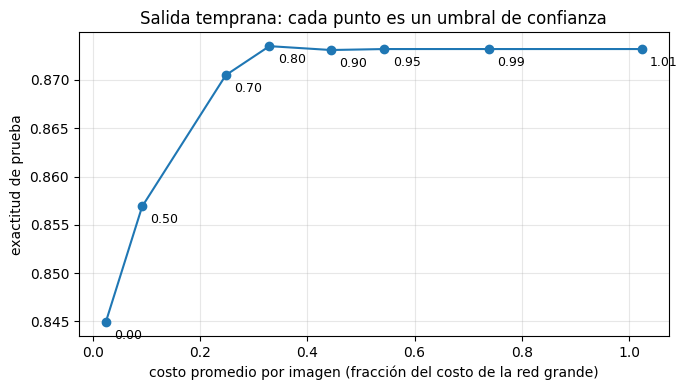

In [25]:
fig, eje = plt.subplots(figsize=(7, 4))
eje.plot([fila[3] for fila in filas], [fila[2] for fila in filas], marker="o")
for umbral, fraccion, exactitud, costo in filas:
    eje.annotate(f"{umbral:.2f}", (costo, exactitud), textcoords="offset points", xytext=(6, -12), fontsize=9)
eje.set_xlabel("costo promedio por imagen (fracción del costo de la red grande)")
eje.set_ylabel("exactitud de prueba")
eje.set_title("Salida temprana: cada punto es un umbral de confianza")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Con umbral 0 ninguna imagen pasa a la red grande: es la red chica sola, con 84.49% de exactitud y un 2.4% del costo de la grande. Con umbral 1.01 pasan todas: es la red grande sola, 87.32%, y cuesta un poco más que ella (102.4%) porque además corre la chica. Entre esos extremos está lo interesante: con umbral 0.8 pasa a la red grande el 30.5% de las imágenes y la exactitud es 87.35%, la misma de la red grande sola para efectos prácticos, con un tercio de su costo. Subir el umbral desde ahí solo agrega costo.

La razón está en la última columna. Cuando la red chica está segura, casi siempre acierta: con umbral 0.8 acierta el 95.5% de las imágenes que se queda, contra 84.5% sobre todas. Las imágenes que manda a la red grande son justamente las difíciles, y para las fáciles la red grande no aporta nada.

Esta red no se puede escribir como un grafo fijo: cuántas imágenes pasan a la red grande, y cuáles, se sabe solo después de ver los datos. En PyTorch es un `if` y una máscara.

## 9. Grafos estáticos

Los *frameworks* antiguos, cuenta el video, trabajaban al revés: primero se define el grafo completo y después se le pasan datos. Eso permite optimizarlo de antemano, pero obliga a declarar todos los caminos posibles antes de empezar. PyTorch también puede capturar un grafo fijo a partir de un modelo, y probarlo es la mejor forma de ver la diferencia.

`torch.fx` es una de esas herramientas. Su documentación ([*Overview*](https://docs.pytorch.org/docs/stable/fx.html#overview)) explica que el trazador simbólico hace una "ejecución simbólica" del código: en vez de datos le pasa valores falsos, llamados *Proxies*, y anota las operaciones que se hacen con ellos. El resultado es un grafo que se puede imprimir como código de Python. Con la red de la sección 7, que no tiene ningún `if`, funciona:

In [26]:
from torch import fx

grafo_fijo = fx.symbolic_trace(red)
print(grafo_fijo.code)
x = X_entrenamiento[:8]
print("¿misma salida que la red original?", torch.equal(grafo_fijo(x), red(x)))




def forward(self, input):
    input_1 = input
    _0 = getattr(self, "0")(input_1);  input_1 = None
    _1 = getattr(self, "1")(_0);  _0 = None
    _2 = getattr(self, "2")(_1);  _1 = None
    _3 = getattr(self, "3")(_2);  _2 = None
    return _3
    
¿misma salida que la red original? True


El grafo capturado es una lista fija de operaciones: aplanar, lineal, ReLU, lineal. Ahora el modelo con salida temprana, cuyo `forward` decide según los datos:

In [27]:
try:
    fx.symbolic_trace(temprana, concrete_args={"umbral": 0.9})
except Exception as error:
    mostrar_error(error)

TraceError:
symbolically traced variables cannot be used as inputs to control flow


Falla. La documentación lo anticipa en [*Limitations of Symbolic Tracing*](https://docs.pytorch.org/docs/stable/fx.html#limitations-of-symbolic-tracing): la principal limitación del trazado simbólico es que no admite **control de flujo dinámico**, es decir, bucles o `if` cuya condición puede depender de los valores de la entrada. Al llegar a `if dificiles.any()`, `dificiles` no es un tensor con valores sino un *Proxy*, y no hay forma de saber si es verdadero o falso.

En cambio, el **control de flujo estático**, el que no depende de los datos, sí se puede trazar ([*Static Control Flow*](https://docs.pytorch.org/docs/stable/fx.html#static-control-flow)). El `if umbral is None` de arriba es de ese tipo, y por eso fijamos el umbral con `concrete_args`. El `if tipo == "ropa"` de la red con dos cabezas también lo es, si se fija el tipo de antemano. Pero entonces el grafo queda con una sola cabeza:

In [28]:
solo_ropa = fx.symbolic_trace(modelo, concrete_args={"tipo": "ropa"})
print(solo_ropa.code)




def forward(self, x, tipo_1):
    eq = tipo_1 == 'ropa';  tipo_1 = None
    _assert = torch._assert(eq, 'tipo has been specialized to have value ropa but got another value');  eq = _assert = None
    tronco_0 = getattr(self.tronco, "0")(x);  x = None
    tronco_1 = getattr(self.tronco, "1")(tronco_0);  tronco_0 = None
    tronco_2 = getattr(self.tronco, "2")(tronco_1);  tronco_1 = None
    cabeza_ropa = self.cabeza_ropa(tronco_2);  tronco_2 = None
    return cabeza_ropa
    


`torch.fx` eligió la rama de ropa y agregó un `_assert` que falla si después se llama con otro tipo. Para tener las dos cabezas en un grafo fijo habría que capturar dos grafos, uno por rama, o reescribir el modelo para calcular las dos cabezas siempre y elegir después. Eso es lo que el video llama construir los condicionales de antemano.

**El peligro de congelar una rama.** Hay una forma peor de fallar que con un error. `torch.jit.trace`, la herramienta de captura de TorchScript, ejecuta el modelo con un ejemplo y graba las operaciones que ocurrieron. Si el modelo tiene un `if`, graba la rama que tomó ese ejemplo y la usa para siempre. Lo probamos con la función `f` de la sección 4, escrita como módulo para que sus pesos sean un parámetro (`torch.jit.trace` no acepta un tensor global que pide gradiente), y trazada con una entrada positiva:

In [29]:
class FuncionConIf(nn.Module):
    """La función f de la sección 4, con los mismos pesos, como módulo."""

    def __init__(self):
        super().__init__()
        self.pesos = nn.Parameter(torch.tensor([1.0, -2.0, 0.5]))

    def forward(self, x):
        z = (self.pesos * x).sum()
        if z > 0:
            return 2 * torch.relu(z)
        return torch.exp(z) - 1


f_modulo = FuncionConIf()
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    f_trazada = torch.jit.trace(f_modulo, x_positivo)

distintos = dict.fromkeys((aviso.category.__name__, str(aviso.message)) for aviso in avisos)
print(f"{len(avisos)} avisos, {len(distintos)} distintos:")
for categoria, mensaje in distintos:
    print(textwrap.fill(f"- {categoria}: {mensaje}", 100, subsequent_indent="  "))
print()
print(f"f(x_negativo)         = {f_modulo(x_negativo).item():8.4f}   (rama exp)")
print(f"f_trazada(x_negativo) = {f_trazada(x_negativo).item():8.4f}   (siguió usando la rama relu)")

5 avisos, 3 distintos:
- DeprecationWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or
  `torch.export`.
- DeprecationWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or
  `torch.export`.
- TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We
  can't record the data flow of Python values, so this value will be treated as a constant in the
  future. This means that the trace might not generalize to other inputs!

f(x_negativo)         =  -0.9502   (rama exp)
f_trazada(x_negativo) =   0.0000   (siguió usando la rama relu)


Capturamos los avisos para mostrarlos (algunos salen repetidos). Dicen dos cosas. La primera, que `torch.jit.trace` está obsoleto en esta versión de PyTorch y conviene pasar a `torch.compile` o `torch.export`. La segunda es la importante: convertir un tensor en un booleano de Python (eso hace el `if z > 0`) puede dejar el trazado incorrecto, porque el trazador no puede registrar el flujo de valores de Python y trata ese valor como una constante, así que el trazado podría no servir para otras entradas. Y no sirvió: con `x_negativo`, la función original toma la rama de la exponencial y da $e^{-3} - 1 \approx -0.95$, mientras la trazada sigue calculando $2\,\mathrm{relu}(z) = 0$. No hay error; solo un número equivocado. Por eso el aviso existe.

La herramienta actual de PyTorch para compilar modelos es `torch.compile`, presentada con PyTorch 2.0. La página [*PyTorch 2.x*](https://pytorch.org/get-started/pytorch-2-x/) cuenta que, en los proyectos de prueba de sus autores, TorchScript y otras herramientas no lograban capturar el grafo ni la mitad de las veces, y que `torch.compile` admite código de PyTorch arbitrario, incluido el control de flujo. Cuando encuentra algo que no puede compilar, como un `if` que depende de los datos o un simple `print`, corta el grafo en pedazos (*graph breaks*), y el código entre pedazos corre como siempre. Lo dinámico no se pierde; solo se acelera menos.

## 10. Lo que cuesta un grafo dinámico

Armar el grafo en cada pasada no es gratis: cada operación pasa por Python y, si algún tensor pide gradiente, además se anota en el grafo. El video lo resume como una pequeña pérdida de rendimiento. Lo medimos de dos formas.

**Anotar o no anotar.** La misma pasada de la red de la sección 7 sobre 256 imágenes, con autograd encendido y dentro de `torch.no_grad()`, que según la documentación hace que las operaciones nunca se registren en el grafo ([*No-grad Mode*](https://docs.pytorch.org/docs/stable/notes/autograd.html#no-grad-mode)):

Medir tiempos chicos es delicado: cualquier otro programa que use la CPU en ese momento los ensucia. Por eso la función de abajo toma tres precauciones. Mide los casos **intercalados**, para que una interrupción no caiga siempre sobre el mismo; repite en varias rondas y se queda con el mejor tiempo de cada caso, que es el menos afectado; y usa **un solo hilo** de la CPU, para que el resultado no dependa de cómo el sistema reparte los núcleos entre programas. Al terminar devuelve a PyTorch la cantidad de hilos que tenía.

In [30]:
def comparar(*casos, rondas):
    """Mejor tiempo por llamada de cada (función, repeticiones), midiendo los casos intercalados."""
    hilos = torch.get_num_threads()
    torch.set_num_threads(1)
    try:
        for funcion, _ in casos:
            funcion()                               # una vez antes, para no medir el arranque
        mejores = [float("inf")] * len(casos)
        for _ in range(rondas):
            for i, (funcion, repeticiones) in enumerate(casos):
                inicio = time.perf_counter()
                for _ in range(repeticiones):
                    funcion()
                mejores[i] = min(mejores[i], (time.perf_counter() - inicio) / repeticiones)
    finally:
        torch.set_num_threads(hilos)
    return mejores


x = X_entrenamiento[:256]


def pasada_con_grafo():
    return red(x)


def pasada_sin_grafo():
    with torch.no_grad():
        return red(x)


t_con, t_sin = comparar((pasada_con_grafo, 20), (pasada_sin_grafo, 20), rondas=30)
print(f"con grafo   : {t_con * 1e6:7.0f} µs por pasada")
print(f"sin grafo   : {t_sin * 1e6:7.0f} µs por pasada")
print(f"anotar el grafo agrega {t_con / t_sin - 1:.0%}")

con grafo   :    1954 µs por pasada
sin grafo   :    1894 µs por pasada
anotar el grafo agrega 3%


Con pocas operaciones grandes, como las multiplicaciones de matrices de una red, anotar el grafo agrega poco: la mayor parte del tiempo se va en la aritmética, que es la misma en los dos casos. El porcentaje exacto cambia de un computador a otro y entre ejecuciones.

**Muchas operaciones chicas.** El costo por operación se nota cuando las operaciones son muchas y diminutas. Sumamos los cuadrados de 2.000 números de dos formas: con un bucle de Python, elemento por elemento, y con una sola operación sobre el tensor completo. Medimos la pasada hacia adelante y `backward()` juntos:

In [31]:
v = torch.randn(2000, requires_grad=True)


def con_bucle():
    total = torch.zeros(())
    for i in range(len(v)):
        total = total + v[i] ** 2
    return total


def vectorizado():
    return (v ** 2).sum()


print("¿el mismo resultado?", torch.allclose(con_bucle(), vectorizado()))
print("nodos del grafo: con bucle", sum(nodos(con_bucle()).values()), "  vectorizado", sum(nodos(vectorizado()).values()))


def con_bucle_y_backward():
    v.grad = None
    con_bucle().backward()


def vectorizado_y_backward():
    v.grad = None
    vectorizado().backward()


t_bucle, t_vector = comparar((con_bucle_y_backward, 1), (vectorizado_y_backward, 100), rondas=3)
print(f"\ncon bucle  : {t_bucle * 1e3:8.2f} ms")
print(f"vectorizado: {t_vector * 1e3:8.3f} ms")
print(f"el bucle es unas {t_bucle / t_vector:,.0f} veces más lento".replace(",", "."))

¿el mismo resultado? True


nodos del grafo: con bucle 6001   vectorizado 3



con bucle  :   298.96 ms
vectorizado:    0.254 ms
el bucle es unas 1.178 veces más lento


El resultado es el mismo, pero el bucle arma un grafo con miles de nodos (por cada elemento, un índice, una potencia y una suma), y cada uno cuesta su anotación en Python y su paso por `backward()`. La versión vectorizada arma un grafo de tres nodos y hace el trabajo en código compilado. La diferencia es del orden de mil veces.

Esta es la regla práctica que deja el grafo dinámico: el costo es **por operación**, así que conviene que las operaciones sean grandes. Se trabaja con lotes completos y con operaciones sobre tensores enteros, y los `if` y los bucles de Python se reservan para decisiones que de verdad lo necesitan, como elegir una cabeza o la cantidad de pasos de una secuencia. El video lo resume diciendo que los frameworks estáticos obligan a pensar como un compilador, mientras que PyTorch deja pensar como un programador de Python.

## 11. Resumen

- Mientras corre `forward`, autograd anota cada operación en un **grafo**. Cada tensor calculado guarda en `grad_fn` el nodo que lo produjo, y `next_functions` lleva a los nodos anteriores. Las hojas que piden gradiente terminan en `AccumulateGrad`; los datos aparecen como `None`.
- El grafo se **arma de nuevo en cada pasada**: los nodos de operación son objetos nuevos; solo los `AccumulateGrad` de los parámetros se repiten.
- `backward()` **libera** los valores guardados del grafo. Un segundo `backward()` sobre el mismo grafo da error, salvo con `retain_graph=True`, y entonces los gradientes se suman.
- Un `if` o un bucle que dependen de los datos producen grafos distintos según la entrada. El grafo contiene la rama que se ejecutó, y el gradiente es el de esa rama: la decisión misma no se deriva.
- En una red con **dos cabezas**, la cabeza que no se usó queda con gradiente `None`, y `Adam` no la mueve.
- Un parámetro usado **varias veces**, como en una secuencia de largo variable, recibe la **suma** de los gradientes de todos sus usos.
- `print` dentro de `forward` funciona porque es Python común. Para módulos sin `forward` propio, como `Sequential`, están los **hooks**: miran, guardan o cambian la salida. Hay que quitarlos con `remove()`.
- La **salida temprana** contesta los casos fáciles con una red chica y manda solo los difíciles a la grande: aquí, con umbral 0.8, logra la exactitud de la red grande con un tercio de su costo.
- Un **grafo estático** no admite control de flujo que dependa de los datos: `torch.fx` da error, y `torch.jit.trace` (obsoleto) congela la rama del ejemplo y da resultados equivocados sin avisar más que con una advertencia.
- El grafo dinámico cuesta un poco **por operación**: poco con operaciones grandes, mucho con miles de operaciones chicas. Por eso se trabaja con tensores enteros.

## Ejercicios

1. Antes de ejecutar: ¿cuántas multiplicaciones tendrá el grafo de `multiplicar_hasta(torch.tensor(0.5), w)` con `w = 3`? Compruébalo con `nodos`.
2. Calcula `rasgos = modelo.tronco(X_entrenamiento[:64])` **una vez**, fuera de un bucle, y después haz dos pasos de entrenamiento de la cabeza de ropa usando esos mismos `rasgos`. ¿Qué error aparece en el segundo paso y por qué? Arréglalo de dos formas: con `rasgos.detach()` (¿qué deja de entrenarse?) y calculando `rasgos` dentro del bucle.
3. Repite el experimento del optimizador de la sección 5 con `torch.optim.SGD(..., momentum=0.9)`: haz primero un paso con un lote de calzado, después llama a `optimizador.zero_grad(set_to_none=False)` y haz un paso con un lote de pura ropa. ¿Se movió la cabeza de calzado en el segundo paso? ¿Y con `set_to_none=True`?
4. Con un hook sobre la ReLU de la red de dos cabezas ya entrenada, guarda las activaciones del tronco para las 10.000 imágenes de prueba. ¿Cuántas de las 128 neuronas no se activan nunca? ¿Hay neuronas que se activen casi solo con ropa, o casi solo con calzado?
5. En la red con salida temprana, con umbral 0.9: ¿qué clases mandan más imágenes a la red grande? ¿Coincide con las clases que la red grande confunde más?
6. Reescribe `DosCabezas` para que su `forward` calcule siempre las dos cabezas para todo el lote y devuelva las dos salidas, y que sea la pérdida la que elija con la máscara `es_ropa`. ¿Ahora sí se puede trazar con `fx.symbolic_trace`? ¿Cuánto cómputo de más hace en cada lote?
7. Mide el bucle de la sección 10 dentro de `torch.no_grad()`. ¿Cuánto del tiempo se iba en anotar el grafo y cuánto en el bucle de Python mismo?

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- El video *Dynamic Graphs* del curso es la base de las secciones 5, 6, 8, 9 y 10: el ejemplo de las cabezas de flores y mariposas, las entradas de largo variable, la red que se adapta a la entrada, los grafos estáticos de los frameworks antiguos y la pequeña pérdida de rendimiento.
- **PyTorch**, [*PyTorch 2.x: faster, more pythonic and as dynamic as ever*](https://pytorch.org/get-started/pytorch-2-x/) (la página de PyTorch 2.x de la lista de lecturas del módulo 1):
  - Sección *TorchDynamo: Acquiring Graphs reliably and fast*: "While TorchScript and others struggled to even acquire the graph 50% of the time, often with a big overhead, TorchDynamo acquired the graph 99% of the time, correctly, safely and with negligible overhead".
  - Sección *Accelerating Hugging Face and TIMM models with PyTorch 2.0*: "torch.compile supports arbitrary PyTorch code, control flow, mutation and comes with experimental support for dynamic shapes."
  - Preguntas frecuentes, *Help my code is running slower with 2.0's Compiled Mode!*: "The most likely reason for performance hits is too many graph breaks. For instance, something innocuous as a print statement in your model's forward triggers a graph break."

**Documentación de PyTorch**

- [*Autograd mechanics*](https://docs.pytorch.org/docs/stable/notes/autograd.html):
  - [*How autograd encodes the history*](https://docs.pytorch.org/docs/stable/notes/autograd.html#how-autograd-encodes-the-history): "autograd records a graph recording all of the operations that created the data as you execute operations, giving you a directed acyclic graph whose leaves are the input tensors and roots are the output tensors", "the .grad_fn attribute of each torch.Tensor is an entry point into this graph" y "An important thing to note is that the graph is recreated from scratch at every iteration, and this is exactly what allows for using arbitrary Python control flow statements, that can change the overall shape and size of the graph at every iteration. You don't have to encode all possible paths before you launch the training - what you run is what you differentiate." (secciones 2, 3 y 4).
  - [*Saved tensors*](https://docs.pytorch.org/docs/stable/notes/autograd.html#saved-tensors): "Some operations need intermediary results to be saved during the forward pass in order to execute the backward pass. For example, the function x ↦ x² saves the input x to compute the gradient." y "You can explore (for educational or debugging purposes) which tensors are saved by a certain grad_fn by looking for its attributes starting with the prefix _saved." (sección 3).
  - [*No-grad Mode*](https://docs.pytorch.org/docs/stable/notes/autograd.html#no-grad-mode): "computations in no-grad mode are never recorded in the backward graph even if there are inputs that have require_grad=True." (sección 10).
- [`torch.fx`](https://docs.pytorch.org/docs/stable/fx.html) (sección 9):
  - [*Overview*](https://docs.pytorch.org/docs/stable/fx.html#overview): "The symbolic tracer performs “symbolic execution” of the Python code. It feeds fake values, called Proxies, through the code. Operations on these Proxies are recorded."
  - [*Dynamic Control Flow*](https://docs.pytorch.org/docs/stable/fx.html#dynamic-control-flow): "The main limitation of symbolic tracing is it does not currently support dynamic control flow. That is, loops or if statements where the condition may depend on the input values of the program."
  - [*Static Control Flow*](https://docs.pytorch.org/docs/stable/fx.html#static-control-flow): "On the other hand, so-called static control flow is supported. Static control flow is loops or if statements whose value cannot change across invocations."
- [`torch.nn.Module.register_forward_hook`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook) (sección 7): "The hook will be called every time after forward() has computed an output.", "The hook can modify the output.", la firma "hook(module, args, output) -> None or modified output" y "Returns: a handle that can be used to remove the added hook by calling handle.remove()".
- Los dos avisos de `torch.jit.trace` de la sección 9 no vienen de una página: son los que imprime PyTorch 2.11 al ejecutar la celda, y están en su salida.

**Lo que no viene de una fuente** son los números de este notebook (gradientes, cantidades de nodos, exactitudes, la tabla de la salida temprana y los tiempos): todos salen de las celdas de código. También son nuestros los ejemplos: el árbol del grafo, la red de dos cabezas con Fashion-MNIST, la recurrencia con un parámetro, la red con salida temprana y las mediciones de costo.